# Language Detection using an RNN

## 1. Imports

In [1]:
from pathlib import Path
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import random
import numpy as np
from collections import Counter
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

warnings.filterwarnings("ignore", category=FutureWarning)

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


I0000 00:00:1791061944.315911    6345 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791061945.090224    6345 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data Loading and Exploration

In [2]:
train_file = str(Path.cwd() / "data/tatoeba/tatoeba/sentences.top10langs.train.tsv")
test_file  = Path.cwd() / "data/tatoeba/tatoeba/sentences.top10langs.dev.tsv"
column_names = ["language_code", "text"]

train_full = pd.read_csv(train_file, sep="\t", header=None, names=column_names, dtype=str, keep_default_na=False)
test_df =  pd.read_csv(test_file, sep="\t", header=None, names=column_names, dtype=str, keep_default_na=False)

print(f"Training shape: {train_full.shape}")
print(f"Test shape:     {test_df.shape}")
display(train_full.head())

Training shape: (99863, 2)
Test shape:     (10000, 2)


,language_code,text
0,spa,"Te di mi corazón para que lo ames, ¡no para us..."
1,spa,Contamos con tu ayuda.
2,spa,Tú eres superficial y materialista.
3,spa,Los límites son para los demás.
4,spa,Todos ellos esperaron ansiosamente las vacacio...


In [3]:
train_full['language_code'].nunique()

10

In [4]:
train_full['language_code'].value_counts()

language_code
spa    10000
deu    10000
tur    10000
fra    10000
epo    10000
ita    10000
hun    10000
ber    10000
eng    10000
por     9863
Name: count, dtype: int64

In [5]:
language_names = {
    "ber": "Berber",
    "deu": "German",
    "eng": "English",
    "epo": "Esperanto",
    "fra": "French",
    "hun": "Hungarian",
    "ita": "Italian",
    "por": "Portuguese",
    "spa": "Spanish",
    "tur": "Turkish",
}

for frame in (train_full, test_df):
    frame["language"] = frame["language_code"].map(language_names)
    frame["character_count"] = frame["text"].str.len()
    frame["word_count"] = frame["text"].str.split().str.len()

display(pd.DataFrame({"code": language_names.keys(),
                      "language": language_names.values()}))

,code,language
0,ber,Berber
1,deu,German
2,eng,English
3,epo,Esperanto
4,fra,French
5,hun,Hungarian
6,ita,Italian
7,por,Portuguese
8,spa,Spanish
9,tur,Turkish


### 2.1 Data quality Checks

In [6]:
quality = pd.DataFrame(
    {
        "split": ["training", "test"],
        "rows": [len(train_full), len(test_df)],
        "missing_language": [
            train_full["language_code"].eq("").sum(),
            test_df["language_code"].eq("").sum(),
        ],
        "missing_text": [
            train_full["text"].eq("").sum(),
            test_df["text"].eq("").sum(),
        ],
        "duplicate_rows": [
            train_full[["language_code", "text"]].duplicated().sum(),
            test_df[["language_code", "text"]].duplicated().sum(),
        ],
    }
)
display(quality)

observed_codes = set(train_full["language_code"].unique())
assert observed_codes == set(language_names), "Unexpected or missing language code."
assert not train_full["text"].eq("").any(), "Empty training text detected."

,split,rows,missing_language,missing_text,duplicate_rows
0,training,99863,0,0,0
1,test,10000,0,0,0


### Class Distribution

,language_code,language,training_examples
0,ber,Berber,10000
2,eng,English,10000
3,epo,Esperanto,10000
4,fra,French,10000
1,deu,German,10000
5,hun,Hungarian,10000
6,ita,Italian,10000
7,por,Portuguese,9863
8,spa,Spanish,10000
9,tur,Turkish,10000


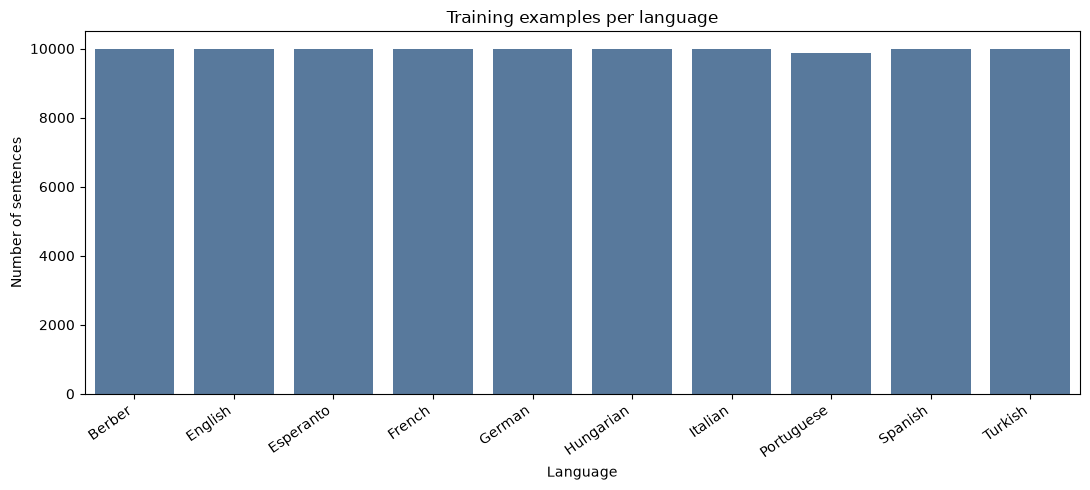

In [7]:
class_counts = (
    train_full.groupby(["language_code", "language"])
    .size()
    .rename("training_examples")
    .reset_index()
    .sort_values("language")
)
display(class_counts)

plt.figure(figsize=(11, 5))
ax = sns.barplot(data=class_counts, x="language", y="training_examples",
                 color="#4C78A8")
ax.set(title="Training examples per language", xlabel="Language",
       ylabel="Number of sentences")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Each language has 10,000 training sentences except Portuguese, which has 9,863

### 2.3 Example sentences

In [8]:
examples = (
    train_full.groupby("language", group_keys=False)
    .sample(n=2, random_state=SEED)
    .sort_values("language")[["language", "text"]]
    .reset_index(drop=True)
)
display(examples)

,language,text
0,Berber,Imsulta ḍḍfen amakar-nni mi yella yettaker.
1,Berber,Tzemreḍ ad iyi-d-teqḍuḍ kra n tɣawsiwin?
2,English,I just wanted to have a good time like anybody...
3,English,Mary is getting leaner and stronger.
4,Esperanto,Ĉu tolerado de doloroj de aliulo ĝenas onin?
5,Esperanto,Kion vi deziras diri per tio?
6,French,Ça clarifie les choses.
7,French,Il me parla à peine.
8,German,"Es scheint, dass sie als Menschen allzu versch..."
9,German,"Tom möchte, dass wir gehen."


### 2.4 Sentence-length analysis

In [9]:
length_summary = train_full[["character_count", "word_count"]].describe(
    percentiles=[0.90, 0.95, 0.975, 0.99, 0.995]
).round(2)
display(length_summary)

character_percentiles = (
    train_full["character_count"]
    .quantile([0.50, 0.90, 0.95, 0.975, 0.99, 0.995, 1.0])
    .rename("characters")
    .to_frame()
)
display(character_percentiles)


,character_count,word_count
count,99863.00,99863.00
mean,37.81,6.54
std,30.22,5.33
min,3.00,1.00
90%,59.00,10.00
95%,74.00,13.00
97.5%,93.00,16.00
99%,127.00,21.00
99.5%,158.00,27.00
max,5833.00,1078.00


,characters
0.500,33.0
0.900,59.0
0.950,74.0
0.975,93.0
0.990,127.0
0.995,158.0
1.000,5833.0


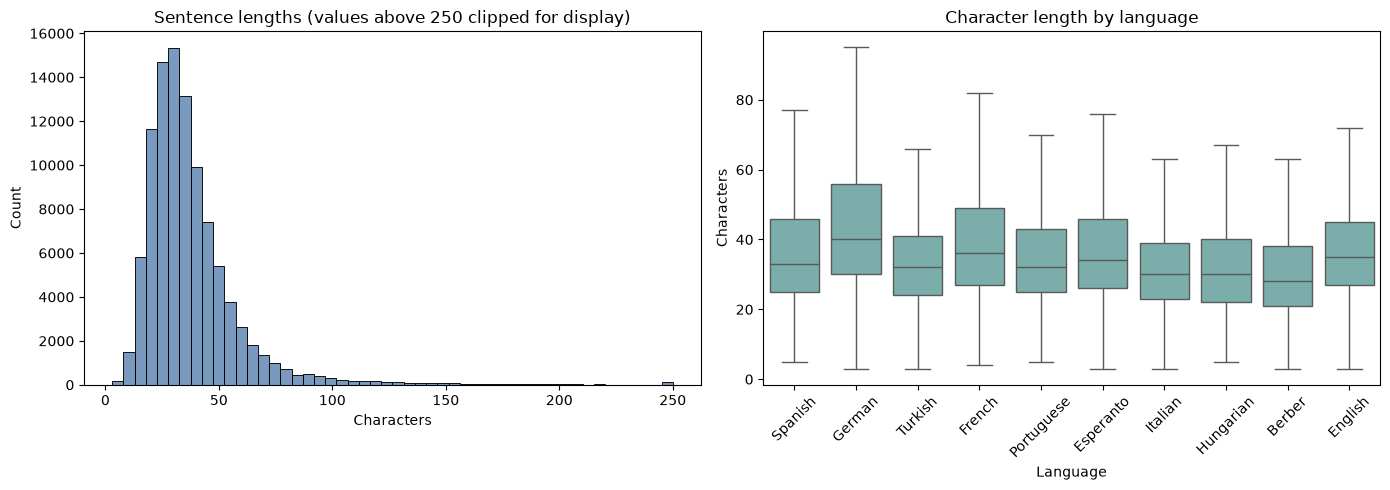

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train_full["character_count"].clip(upper=250), bins=50,
             ax=axes[0], color="#4C78A8")
axes[0].set(
    title="Sentence lengths (values above 250 clipped for display)",
    xlabel="Characters",
)

sns.boxplot(data=train_full, x="language", y="character_count",
            showfliers=False, ax=axes[1], color="#72B7B2")
axes[1].set(title="Character length by language", xlabel="Language",
            ylabel="Characters")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [11]:
# Avoid extreme outliers.
percentile_995 = train_full["character_count"].quantile(0.995)
max_length = int(np.ceil(percentile_995 / 10) * 10)
max_length = int(np.clip(max_length, 80, 200))

retained = (train_full["character_count"] <= max_length).mean()
print("Selected maximum sequence length:", max_length)
print(f"Training sentences fully retained: {retained:.2%}")
print("Maximum observed length:", train_full["character_count"].max())

Selected maximum sequence length: 160
Training sentences fully retained: 99.52%
Maximum observed length: 5833


The maximum observed length is an outlier. A 160 character length will preserve 99.5% of the training sentences. 

### 2.5 Character Analysis

In [12]:
character_counts = Counter("".join(train_full["text"]))
print("Distinct characters in the complete training file:", len(character_counts))

common_characters = pd.DataFrame(
    character_counts.most_common(30), columns=["character", "count"]
)
common_characters["display"] = common_characters["character"].map(repr)
display(common_characters[["display", "count"]])

Distinct characters in the complete training file: 236


,display,count
0,' ',552196
1,'e',360032
2,'a',295875
3,'i',220968
4,'n',215364
5,'o',200397
6,'s',185072
7,'t',182485
8,'r',172560
9,'l',133886


## 3. Preprocessing

In [13]:
model_columns = ["language_code", "text"]
train_df, validation_df = train_test_split(
    train_full[model_columns],
    test_size=0.10,
    random_state=SEED,
    stratify=train_full["language_code"],
)
train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
held_out_df = test_df[model_columns].reset_index(drop=True)

print("Training rows:  ", f"{len(train_df):,}")
print("Validation rows:", f"{len(validation_df):,}")
print("Held-out rows:  ", f"{len(held_out_df):,}")

Training rows:   89,876
Validation rows: 9,987
Held-out rows:   10,000


In [14]:
character_tokenizer = Tokenizer(
    char_level=True,
    lower=False,
    filters=None,
    oov_token="<UNK>",
)
character_tokenizer.fit_on_texts(train_df["text"])

label_encoder = LabelEncoder()
label_encoder.fit(train_df["language_code"])

class_codes = list(label_encoder.classes_)
class_names = [language_names[code] for code in class_codes]
n_classes = len(class_codes)
vocab_size = len(character_tokenizer.word_index) + 1

def encode_texts(texts):
    sequences = character_tokenizer.texts_to_sequences(list(texts))
    return pad_sequences(
        sequences,
        maxlen=max_length,
        padding="post",
        truncating="post",
        value=0,
    ).astype("int32")

X_train = encode_texts(train_df["text"])
X_validation = encode_texts(validation_df["text"])
X_test = encode_texts(held_out_df["text"])

y_train = label_encoder.transform(train_df["language_code"])
y_validation = label_encoder.transform(validation_df["language_code"])
y_test = label_encoder.transform(held_out_df["language_code"])

print("Character vocabulary size (including padding):", vocab_size)
print("Class order:", dict(enumerate(class_names)))
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_validation:", X_validation.shape, "y_validation:", y_validation.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Character vocabulary size (including padding): 236
Class order: {0: 'Berber', 1: 'German', 2: 'English', 3: 'Esperanto', 4: 'French', 5: 'Hungarian', 6: 'Italian', 7: 'Portuguese', 8: 'Spanish', 9: 'Turkish'}
X_train: (89876, 160) y_train: (89876,)
X_validation: (9987, 160) y_validation: (9987,)
X_test: (10000, 160) y_test: (10000,)


In [15]:
example_index = 0
example_text = train_df.loc[example_index, "text"]
example_sequence = character_tokenizer.texts_to_sequences([example_text])[0]

print("Original text:")
print(example_text)
print("\nFirst 40 character IDs before padding:")
print(example_sequence[:40])
print("\nFirst 40 positions after padding/truncation:")
print(X_train[example_index, :40])
print("\nEncoded label:", y_train[example_index],
      "->", class_names[y_train[example_index]])

Original text:
Elles sont armées.

First 40 character IDs before padding:
[39, 11, 11, 3, 8, 2, 8, 7, 6, 9, 2, 4, 10, 12, 29, 3, 8, 15]

First 40 positions after padding/truncation:
[39 11 11  3  8  2  8  7  6  9  2  4 10 12 29  3  8 15  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]

Encoded label: 4 -> French


## 4. Modeling

In [16]:
embedding_dim = 32
rnn_units = 48
batch_size = 256
max_epochs = 35

def compile_model(model):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def build_simple_rnn():
    model = keras.Sequential(
        [
            keras.layers.Input(shape=(max_length,), dtype="int32"),
            keras.layers.Embedding(
                vocab_size, embedding_dim, mask_zero=True, name="char_embedding"
            ),
            keras.layers.SimpleRNN(rnn_units, name="simple_rnn"),
            keras.layers.Dropout(0.30),
            keras.layers.Dense(64, activation="relu"),
            keras.layers.Dropout(0.20),
            keras.layers.Dense(n_classes, activation="softmax"),
        ],
        name="character_simple_rnn",
    )
    return compile_model(model)


def build_bidirectional_gru():
    model = keras.Sequential(
        [
            keras.layers.Input(shape=(max_length,), dtype="int32"),
            keras.layers.Embedding(
                vocab_size, embedding_dim, mask_zero=True, name="char_embedding"
            ),
            keras.layers.Bidirectional(
                keras.layers.GRU(rnn_units), name="bidirectional_gru"
            ),
            keras.layers.Dropout(0.30),
            keras.layers.Dense(64, activation="relu"),
            keras.layers.Dropout(0.20),
            keras.layers.Dense(n_classes, activation="softmax"),
        ],
        name="character_bidirectional_gru",
    )
    return compile_model(model)


def training_callbacks():
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5
        ),
    ]

### 4.1 SimpleRNN baseline

In [17]:
simple_rnn = build_simple_rnn()
simple_rnn.summary()

simple_history = simple_rnn.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=max_epochs,
    batch_size=batch_size,
    callbacks=training_callbacks(),
    verbose=2,
)

Model: "character_simple_rnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ char_embedding (Embedding)      │ (None, 160, 32)        │         7,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 48)             │         3,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,226 (59.48 KB)

 Trainable params: 15,226 (59.48 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/35
352/352 - 12s - 34ms/step - accuracy: 0.4688 - loss: 1.3858 - val_accuracy: 0.6464 - val_loss: 0.9433 - learning_rate: 0.0010
Epoch 2/35
352/352 - 4s - 11ms/step - accuracy: 0.7098 - loss: 0.7824 - val_accuracy: 0.7922 - val_loss: 0.5731 - learning_rate: 0.0010
Epoch 3/35
352/352 - 4s - 11ms/step - accuracy: 0.7702 - loss: 0.6343 - val_accuracy: 0.8221 - val_loss: 0.4848 - learning_rate: 0.0010
Epoch 4/35
352/352 - 4s - 10ms/step - accuracy: 0.7981 - loss: 0.5645 - val_accuracy: 0.8468 - val_loss: 0.4298 - learning_rate: 0.0010
Epoch 5/35
352/352 - 4s - 10ms/step - accuracy: 0.8174 - loss: 0.5120 - val_accuracy: 0.8584 - val_loss: 0.3917 - learning_rate: 0.0010
Epoch 6/35
352/352 - 4s - 10ms/step - accuracy: 0.8343 - loss: 0.4683 - val_accuracy: 0.8756 - val_loss: 0.3545 - learning_rate: 0.0010
Epoch 7/35
352/352 - 4s - 11ms/step - accuracy: 0.8453 - loss: 0.4397 - val_accuracy: 0.8789 - val_loss: 0.3321 - learning_rate: 0.0010
Epoch 8/35
352/352 - 4s - 10ms/step - accuracy:

### 4.2 Bidirectional GRU

In [18]:
bidirectional_gru = build_bidirectional_gru()
bidirectional_gru.summary()

gru_history = bidirectional_gru.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=max_epochs,
    batch_size=batch_size,
    callbacks=training_callbacks(),
    verbose=2,
)

Model: "character_bidirectional_gru"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ char_embedding (Embedding)      │ (None, 160, 32)        │         7,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_gru               │ (None, 96)             │        23,616 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,026 (148.54 KB)

 Trainable params: 38,026 (148.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/35
352/352 - 5s - 14ms/step - accuracy: 0.6540 - loss: 0.9923 - val_accuracy: 0.8408 - val_loss: 0.4569 - learning_rate: 0.0010
Epoch 2/35
352/352 - 3s - 8ms/step - accuracy: 0.8462 - loss: 0.4407 - val_accuracy: 0.8807 - val_loss: 0.3368 - learning_rate: 0.0010
Epoch 3/35
352/352 - 3s - 8ms/step - accuracy: 0.8815 - loss: 0.3334 - val_accuracy: 0.9047 - val_loss: 0.2625 - learning_rate: 0.0010
Epoch 4/35
352/352 - 3s - 8ms/step - accuracy: 0.9048 - loss: 0.2680 - val_accuracy: 0.9273 - val_loss: 0.2036 - learning_rate: 0.0010
Epoch 5/35
352/352 - 3s - 8ms/step - accuracy: 0.9244 - loss: 0.2158 - val_accuracy: 0.9391 - val_loss: 0.1671 - learning_rate: 0.0010
Epoch 6/35
352/352 - 3s - 8ms/step - accuracy: 0.9379 - loss: 0.1796 - val_accuracy: 0.9487 - val_loss: 0.1439 - learning_rate: 0.0010
Epoch 7/35
352/352 - 3s - 8ms/step - accuracy: 0.9475 - loss: 0.1529 - val_accuracy: 0.9533 - val_loss: 0.1342 - learning_rate: 0.0010
Epoch 8/35
352/352 - 3s - 8ms/step - accuracy: 0.9551 

### 4.3 Learning Curves

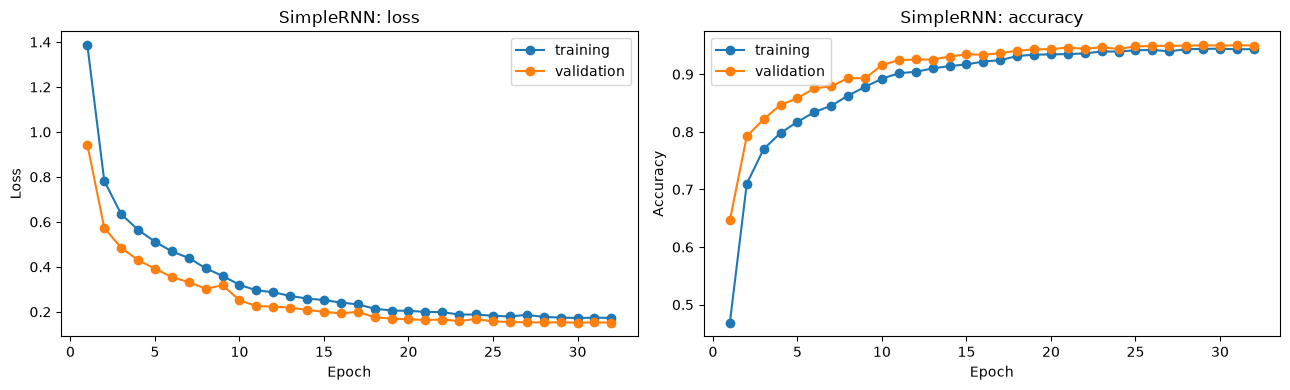

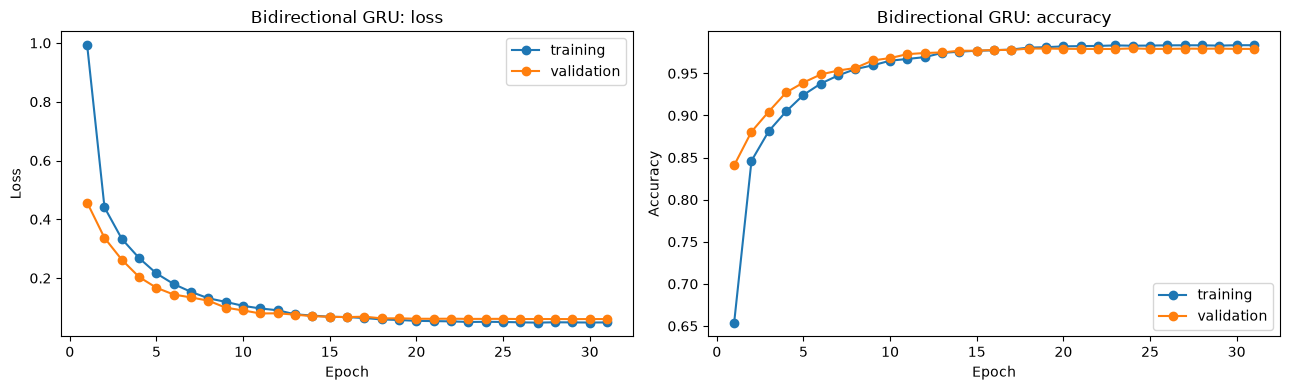

In [19]:
def plot_history(history, title):
    history_df = pd.DataFrame(history.history)
    epochs = np.arange(1, len(history_df) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(epochs, history_df["loss"], marker="o", label="training")
    axes[0].plot(epochs, history_df["val_loss"], marker="o", label="validation")
    axes[0].set(title=f"{title}: loss", xlabel="Epoch", ylabel="Loss")
    axes[0].legend()

    axes[1].plot(epochs, history_df["accuracy"], marker="o", label="training")
    axes[1].plot(epochs, history_df["val_accuracy"], marker="o", label="validation")
    axes[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


plot_history(simple_history, "SimpleRNN")
plot_history(gru_history, "Bidirectional GRU")

### 4.4 Validation comparison and model selection
We will select the final model using Macro-F1. It gives each language equal influence despite small class count differences.

In [20]:
candidate_models = {
    "SimpleRNN": simple_rnn,
    "Bidirectional GRU": bidirectional_gru,
}

validation_rows = []
for name, model in candidate_models.items():
    probabilities = model.predict(X_validation, batch_size=512, verbose=0)
    predictions = probabilities.argmax(axis=1)
    validation_rows.append(
        {
            "model": name,
            "validation_accuracy": accuracy_score(y_validation, predictions),
            "validation_macro_f1": f1_score(
                y_validation, predictions, average="macro"
            ),
        }
    )

validation_results = (
    pd.DataFrame(validation_rows)
    .sort_values("validation_macro_f1", ascending=False)
    .reset_index(drop=True)
)
display(validation_results.style.format({
    "validation_accuracy": "{:.4f}",
    "validation_macro_f1": "{:.4f}",
}))

best_model_name = validation_results.loc[0, "model"]
best_model = candidate_models[best_model_name]
print("Selected model:", best_model_name)

,model,validation_accuracy,validation_macro_f1
0,Bidirectional GRU,0.9794,0.9793
1,SimpleRNN,0.9497,0.9496


Selected model: Bidirectional GRU


## 5. Held-out evaluation and error analysis

In [21]:
test_probabilities = best_model.predict(X_test, batch_size=512, verbose=0)
test_predictions = test_probabilities.argmax(axis=1)
test_confidence = test_probabilities.max(axis=1)

test_metrics = pd.Series(
    {
        "accuracy": accuracy_score(y_test, test_predictions),
        "macro_precision": precision_score(
            y_test, test_predictions, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_test, test_predictions, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_test, test_predictions, average="macro", zero_division=0
        ),
    },
    name=best_model_name,
)
display(test_metrics.to_frame().style.format("{:.4f}"))

print(classification_report(
    y_test,
    test_predictions,
    labels=np.arange(n_classes),
    target_names=class_names,
    digits=4,
    zero_division=0,
))

,Bidirectional GRU
accuracy,0.9826
macro_precision,0.9826
macro_recall,0.9826
macro_f1,0.9826


              precision    recall  f1-score   support

      Berber     0.9880    0.9920    0.9900      1000
      German     0.9831    0.9910    0.9871      1000
     English     0.9929    0.9850    0.9890      1000
   Esperanto     0.9851    0.9900    0.9875      1000
      French     0.9889    0.9820    0.9854      1000
   Hungarian     0.9899    0.9820    0.9859      1000
     Italian     0.9703    0.9800    0.9751      1000
  Portuguese     0.9748    0.9660    0.9704      1000
     Spanish     0.9600    0.9610    0.9605      1000
     Turkish     0.9930    0.9970    0.9950      1000

    accuracy                         0.9826     10000
   macro avg     0.9826    0.9826    0.9826     10000
weighted avg     0.9826    0.9826    0.9826     10000



### 5.1 Confusion matrix

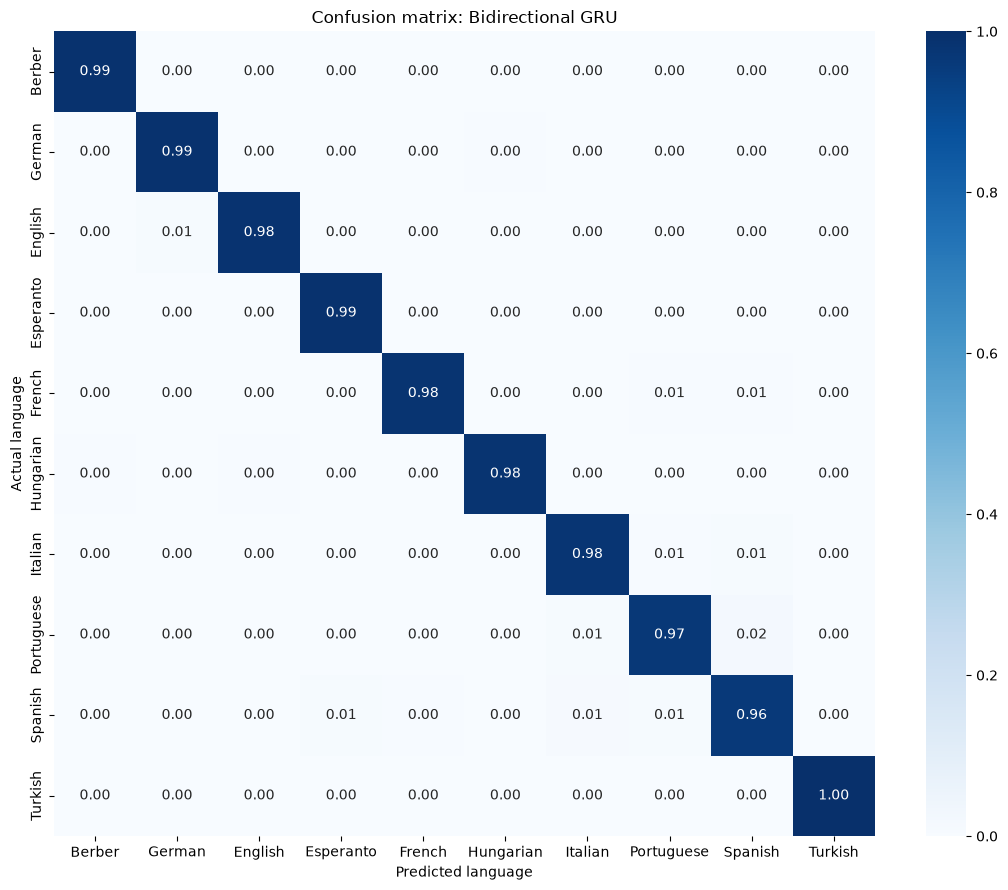

In [22]:
normalized_cm = confusion_matrix(
    y_test, test_predictions, labels=np.arange(n_classes), normalize="true"
)

plt.figure(figsize=(11, 9))
sns.heatmap(
    normalized_cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1,
)
plt.title(f"Confusion matrix: {best_model_name}")
plt.xlabel("Predicted language")
plt.ylabel("Actual language")
plt.tight_layout()
plt.show()

### 5.2 Most frequent confusion pairs

In [23]:
raw_cm = confusion_matrix(
    y_test, test_predictions, labels=np.arange(n_classes)
)
confusion_rows = []
for actual in range(n_classes):
    for predicted in range(n_classes):
        if actual != predicted and raw_cm[actual, predicted] > 0:
            confusion_rows.append(
                {
                    "actual": class_names[actual],
                    "predicted": class_names[predicted],
                    "count": raw_cm[actual, predicted],
                }
            )

confusion_pairs = (
    pd.DataFrame(confusion_rows)
    .sort_values("count", ascending=False)
    .head(12)
    .reset_index(drop=True)
)
display(confusion_pairs)

,actual,predicted,count
0,Portuguese,Spanish,21
1,Spanish,Italian,15
2,Italian,Spanish,9
3,Spanish,Esperanto,9
4,English,German,8
5,Portuguese,Italian,8
6,Spanish,Portuguese,8
7,Italian,Portuguese,6
8,French,Spanish,6
9,French,Portuguese,5


## 6. Interpretation with LIME

In [24]:
from lime.lime_text import LimeTextExplainer

def predict_raw_text(texts):
    encoded = encode_texts(texts)
    return best_model.predict(encoded, batch_size=512, verbose=0)

correct_mask = y_test == test_predictions
medium_length_mask = held_out_df["text"].str.len().between(25, 70).to_numpy()
eligible = np.flatnonzero(correct_mask & medium_length_mask)
if len(eligible) == 0:
    eligible = np.flatnonzero(correct_mask)

explanation_index = eligible[np.argmax(test_confidence[eligible])]
explanation_text = held_out_df.loc[explanation_index, "text"]
explanation_actual = y_test[explanation_index]
explanation_prediction = test_predictions[explanation_index]

print("Text:", explanation_text)
print("Actual:", class_names[explanation_actual])
print("Predicted:", class_names[explanation_prediction])
print("Confidence:", f"{test_confidence[explanation_index]:.4f}")

Text: O que é que aconteceu com o cabelo do senhor?
Actual: Portuguese
Predicted: Portuguese
Confidence: 1.0000


,character_or_position,LIME_weight
0,o,+0.12596
1,o,+0.11720
2,O,+0.11592
3,o,+0.10641
4,u,+0.09955
5,h,+0.08706
6,s,+0.08508
7,u,+0.08485
8,o,+0.08202
9,o,+0.06019


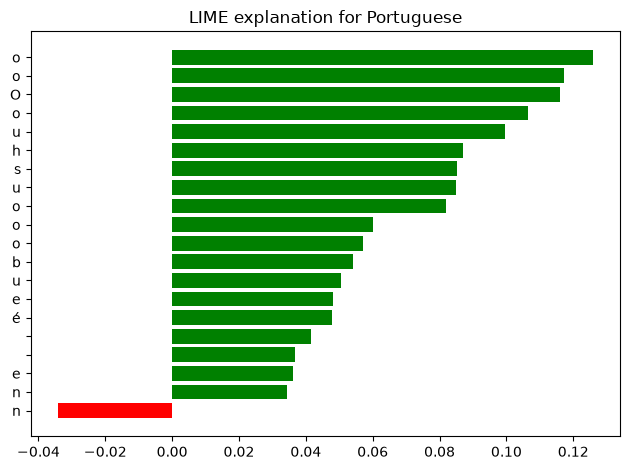

In [25]:
lime_explainer = LimeTextExplainer(
    class_names=class_names,
    char_level=True,
    bow=False,
    random_state=SEED,
)

lime_explanation = lime_explainer.explain_instance(
    explanation_text,
    predict_raw_text,
    labels=[int(explanation_prediction)],
    num_features=min(20, len(explanation_text)),
    num_samples=1000,
)

lime_table = pd.DataFrame(
    lime_explanation.as_list(label=int(explanation_prediction)),
    columns=["character_or_position", "LIME_weight"],
)
display(lime_table.style.format({"LIME_weight": "{:+.5f}"}))

lime_explanation.as_pyplot_figure(label=int(explanation_prediction))
plt.title(f"LIME explanation for {class_names[explanation_prediction]}")
plt.tight_layout()
plt.show()

Many characters contributed to the Portuguese classification. An occurence of n opposed but other occurrences of n supported it. This shows that the predictions depend on position and context rather than an indipendent character by itself. 

## 7. Interpretation with SHAP 

In [26]:
import shap

def predict_encoded(encoded_sequences):
    encoded_sequences = np.asarray(encoded_sequences, dtype=np.int32)
    return best_model(encoded_sequences, training=False).numpy()


encoded_explanation = encode_texts([explanation_text])
encoded_length = int(np.count_nonzero(encoded_explanation[0]))

space_id = character_tokenizer.word_index[" "]

shap_reference = np.zeros_like(encoded_explanation)
shap_reference[0, :encoded_length] = space_id

print("Reference prediction shape:", predict_encoded(shap_reference).shape)

shap_explainer = shap.KernelExplainer(
    predict_encoded,
    shap_reference,
    feature_names=[f"position_{i}" for i in range(max_length)],
)

shap_output = shap_explainer.shap_values(
    encoded_explanation,
    nsamples=250,
    l1_reg="num_features(20)",
    silent=True,
)

Reference prediction shape: (1, 10)


/home/peter-kabati/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,position,character,SHAP_value
14,33,'o',-0.070036
13,9,'u',-0.068301
0,40,'n',+0.004008
1,22,'c',+0.007717
2,44,'?',+0.013277
3,43,'r',+0.015827
4,13,'c',+0.019876
5,14,'o',+0.022023
6,41,'h',+0.027388
7,17,'e',+0.029054


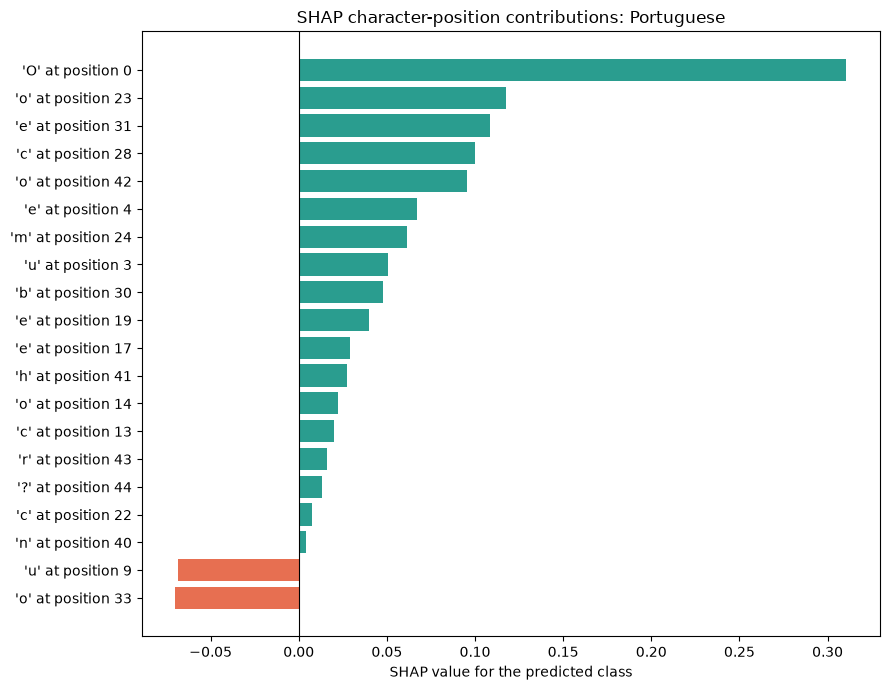

In [27]:
shap_array = np.asarray(shap_output)

expected_shape = (1, max_length, n_classes)

if shap_array.shape != expected_shape:
    raise ValueError(
        f"Expected SHAP output shape {expected_shape}, "
        f"but received {shap_array.shape}."
    )

class_index = int(explanation_prediction)
class_shap = shap_array[0, :, class_index]

characters = list(explanation_text[:max_length])
character_shap = class_shap[:len(characters)]

top_count = min(20, len(characters))
top_positions = np.argsort(
    np.abs(character_shap)
)[-top_count:]

shap_table = pd.DataFrame(
    {
        "position": top_positions,
        "character": [
            repr(characters[position])
            for position in top_positions
        ],
        "SHAP_value": character_shap[top_positions],
    }
).sort_values("SHAP_value")

display(
    shap_table.style.format(
        {"SHAP_value": "{:+.6f}"}
    )
)

colors = np.where(
    shap_table["SHAP_value"] >= 0,
    "#2A9D8F",
    "#E76F51",
)

labels = [
    f"{row.character} at position {row.position}"
    for row in shap_table.itertuples()
]

plt.figure(figsize=(9, 7))

plt.barh(
    labels,
    shap_table["SHAP_value"],
    color=colors,
)

plt.axvline(
    0,
    color="black",
    linewidth=0.8,
)

plt.title(
    "SHAP character-position contributions: "
    f"{class_names[class_index]}"
)

plt.xlabel("SHAP value for the predicted class")
plt.tight_layout()
plt.show()

The Portuguese prediction was supported most strongly by O at position 0. Different contributions for repeated letters show that the model uses position and context for its predictions. 